In [1]:
import os

print(os.listdir())

[' p3 not.ipynb', '.agents', '.anaconda', '.antigravity-ide', '.aws', '.azd', '.azure', '.bash_history', '.cache', '.cagent', '.conda', '.condarc', '.config', '.continuum', '.copilot', '.docker', '.eclipse', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.m2', '.matplotlib', '.ms-ad', '.nbi', '.p2', '.python_history', '.qoder', '.streamlit', '.TurboVPN', '.VirtualBox', '.vscode', '.vscode-shared', 'anaconda3', 'AppData', 'Application Data', 'Ashritha', 'aws', 'awscliv2.zip', 'bfs', 'breast_cancer_wisconsin_diagnostic.xlsx', 'california house.ipynb', 'cleaned_employees.csv', 'Contacts', 'Cookies', 'Data Cleaning & Visualization Project,.ipynb', 'Documents', 'Downloads', 'eclipse', 'employees.csv', 'Favorites', 'GlassFish_Server', 'GlassFish_Server1', 'housing.csv', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.DAT{2a

In [3]:

import pandas as pd

df = pd.read_excel("breast_cancer_wisconsin_diagnostic.xlsx")

df.head()


,ID,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,2,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,3,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,4,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,5,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [5]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDiagnosis counts:")
print(df["Diagnosis"].value_counts())


Dataset shape: (569, 32)

Column names:
Index(['ID', 'mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'Diagnosis'],
      dtype='object')

Missing values:
0

Diagnosis counts:
Diagnosis
benign       357
malignant    212
Name: count, dtype: int64


In [7]:


X = df.drop(columns=["ID", "Diagnosis"])
y = df["Diagnosis"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)


Input features shape: (569, 30)
Target shape: (569,)


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


In [11]:

from sklearn.linear_model import LogisticRegression


model = LogisticRegression(max_iter=10000)

 
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [13]:


y_pred = model.predict(X_test)

print("Actual diagnosis:")
print(y_test.head(10).tolist())

print("\nPredicted diagnosis:")
print(y_pred[:10])


Actual diagnosis:
['benign', 'malignant', 'benign', 'malignant', 'benign', 'benign', 'malignant', 'benign', 'benign', 'benign']

Predicted diagnosis:
['benign' 'malignant' 'benign' 'malignant' 'malignant' 'benign' 'benign'
 'benign' 'benign' 'benign']


In [15]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 93.86 %


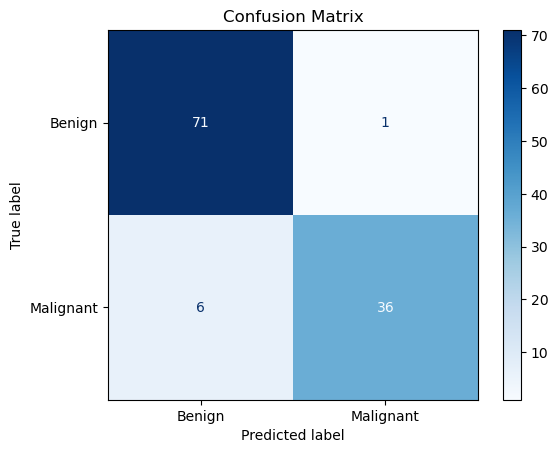

[[71  1]
 [ 6 36]]


In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["benign", "malignant"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

print(cm)


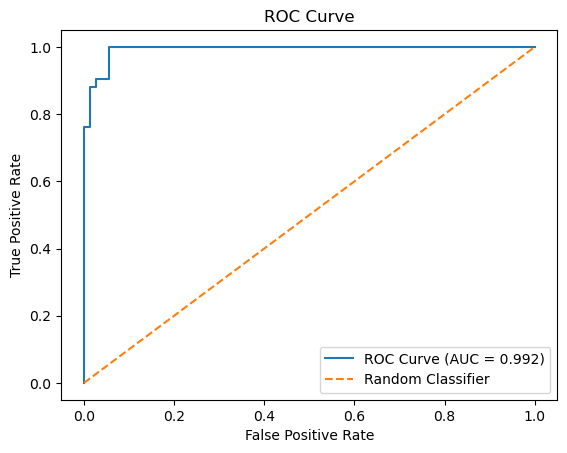

AUC Score: 0.9924


In [19]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


y_test_binary = (y_test == "malignant").astype(int)


y_prob = model.predict_proba(X_test)[:, list(model.classes_).index("malignant")]


fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)
auc_score = roc_auc_score(y_test_binary, y_prob)


plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("AUC Score:", round(auc_score, 4))


In [21]:
print("AUC Score:", round(auc_score, 4))

AUC Score: 0.9924
